# Пример: языковая модель следующего слова на Elman RNN

Этот ноутбук — полный воспроизводимый маршрут от потокового текста до
обученной словарной языковой модели. Он использует поле «text» и первые
1 200 документов потока Gazeta версии «v1.0». Самостоятельный ноутбук
использует отдельный литературный RuHeritage-Corpus с закреплённой
версией, поэтому не является повторением этого эксперимента.

## Как читать ноутбук

Выполняйте ячейки строго сверху вниз. В языковой модели вход и цель —
не метки классов документа. Вход «input_ids» содержит индексы уже
прочитанных токенов, а «target_ids» содержит индексы следующих токенов,
сдвинутые на одну позицию. Общий интерфейс обучения в PyTorch — это
цикл мини-пакетов, а не метод «fit»: прямой проход создаёт логиты,
функция потерь сравнивает их с целями, «backward()» вычисляет
градиенты, «step()» обновляет параметры.

На каждом этапе в Markdown явно названы входы, выходы и проверка.
Полный математический контекст дан в лекции «Рекуррентные нейронные
сети», особенно в разделах об Elman RNN, эмбеддингах и языковой модели.

**Выполненная копия.** Исходный файл сохранён. Для совместимости с datasets 5 используется встроенный JSON-загрузчик того же файла Gazeta v1.0; подборка и гиперпараметры не изменены. Запуск на Python 3.12 и PyTorch 2.13.0, устройство CPU. Перплексия вычисляется как exp(loss) без ограничения показателя. Исходные документы не сохраняются в папку работы.


## Этап 1. Настройка воспроизводимого CPU-эксперимента

**Зачем нужен этап.** В этой ячейке фиксируются все константы,
влияющие на эксперимент. Без них нельзя объяснить, почему два запуска
различаются, и нельзя честно сопоставлять потери.
«MAX_DOCUMENTS» задаёт число просмотренных потоковых документов;
«MAX_WORDS_PER_DOCUMENT» ограничивает вклад одного длинного текста;
«MAX_SEQUENCE_LENGTH» — наибольшую длину входной последовательности.
При первом запуске можно временно уменьшить первые две величины, но
итог эксперимента тогда относится уже к уменьшенной подвыборке.

**Входа модели здесь ещё нет.** Результатом являются настроенные
константы и генераторы. Модель обучается на CPU. Фиксация генераторов
случайных чисел делает
порядок мини-пакетов и начальную инициализацию повторяемыми настолько,
насколько это позволяет среда выполнения. **Проверьте:** вывод
содержит версию PyTorch, устройство CPU, имя корпуса, ревизию и поле.

In [1]:
from __future__ import annotations

import copy
import math
import random
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import load_dataset
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

SEED = 42
DATASET_NAME = 'IlyaGusev/gazeta'
DATASET_REVISION = 'v1.0'
TEXT_FIELD = 'text'
START_DOCUMENT = 0
MAX_DOCUMENTS = 1_200
MAX_WORDS_PER_DOCUMENT = 160
MAX_ORDINARY_WORDS = 6_000
MAX_SEQUENCE_LENGTH = 32
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
NUM_LAYERS = 2
BATCH_SIZE = 64
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 12
PATIENCE = 3

SPECIAL_TOKENS = ['<pad>', '<unk>', '<bos>', '<eos>']
PAD_IDX, UNK_IDX, BOS_IDX, EOS_IDX = range(4)
DEVICE = torch.device('cpu')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(4, torch.get_num_threads())))

print(f'PyTorch: {torch.__version__}; устройство: {DEVICE}')
print(f'Поток: {DATASET_NAME}@{DATASET_REVISION}; поле: {TEXT_FIELD}')
import json, sys, time, platform
import datasets
ARTIFACT_DIR = Path("artifacts/example")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
experiment_start = time.perf_counter()
print("Python:", sys.version.split()[0], "datasets:", datasets.__version__)


Matplotlib is building the font cache; this may take a moment.


/private/tmp/linear-algebra-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.13.0; устройство: cpu
Поток: IlyaGusev/gazeta@v1.0; поле: text
Python: 3.12.14 datasets: 5.2.0


## Этап 2. Получение документов и нормализация текста

**Вход:** строка из поля «text» выбранного документа. Нормализатор
приводит её к
нижнему регистру и выделяет русские слова; выход — список строковых
токенов длиной не более «MAX_WORDS_PER_DOCUMENT». Документы с номерами
0, 6, 12 и так далее образуют валидационную часть, остальные —
обучающую. Счёт ведётся по документам потока, а не по уже
отфильтрованным фрагментам.

**Действие:** поток не выгружается целиком: цикл останавливается после ровно
ограниченного участка. Выведите несколько слов и числа документов.
Это первая контрольная точка: должна получиться непустая обучающая и
валидационная части. **Математический результат:** текст пока
представляется дискретной последовательностью слов
$(w_1,\ldots,w_N)$; числа, векторы и веса сети на этом этапе ещё не
возникают. Каждый шестой документ откладывается, чтобы валидационная
потеря измеряла качество на строках, не использованных при шаге AdamW.

In [2]:
WORD_RE = re.compile(r'[а-яё]+(?:-[а-яё]+)?', flags=re.IGNORECASE)


def normalize_and_tokenize(text: str, max_words: int) -> list[str]:
    normalized = ' '.join(str(text).lower().split())
    return WORD_RE.findall(normalized)[:max_words]


def load_documents(
    text_field: str,
    start_document: int,
    max_documents: int,
    max_words: int,
) -> tuple[list[list[str]], list[list[str]]]:
    # v1.0 содержит JSONL и старый загрузочный скрипт. Читаем тот же
    # train-файл закреплённой версии встроенным JSON-загрузчиком datasets.
    stream = load_dataset(
        "json", data_files={"train": f"https://huggingface.co/datasets/{DATASET_NAME}/resolve/{DATASET_REVISION}/gazeta_train.jsonl"},
        split="train", streaming=True,
    )
    train_documents: list[list[str]] = []
    val_documents: list[list[str]] = []
    stop_document = start_document + max_documents

    for document_index, row in enumerate(stream):
        if document_index < start_document:
            continue
        if document_index >= stop_document:
            break
        tokens = normalize_and_tokenize(row.get(text_field, ''), max_words)
        if len(tokens) < 2:
            continue
        if (document_index - start_document) % 6 == 0:
            val_documents.append(tokens)
        else:
            train_documents.append(tokens)

    if not train_documents or not val_documents:
        raise RuntimeError('Не удалось получить обе части выбранной подвыборки.')
    return train_documents, val_documents


train_documents, val_documents = load_documents(
    TEXT_FIELD,
    START_DOCUMENT,
    MAX_DOCUMENTS,
    MAX_WORDS_PER_DOCUMENT,
)

print(f'Обучающих документов: {len(train_documents)}')
print(f'Валидационных документов: {len(val_documents)}')
print('Пример нормализованных токенов:', train_documents[0][:20])

Обучающих документов: 1000
Валидационных документов: 200
Пример нормализованных токенов: ['российское', 'подразделение', 'интернет-корпорации', 'возглавила', 'юлия', 'соловьева', 'экс-директор', 'московского', 'офиса', 'международной', 'консалтинговой', 'компании', 'соловьева', 'приступит', 'к', 'обязанностям', 'генерального', 'директора', 'января', 'сообщили']


## Этап 3. Словарь обучающих токенов без утечки данных

**Вход:** список **обучающих** документов.
Результат — два взаимно обратных соответствия: «stoi» переводит токен
в индекс, «itos» — индекс в токен. Первые четыре позиции
зарезервированы и должны равняться 0, 1, 2, 3. Максимум 6 000 обычных
слов выбирается по частоте только в обучающей части.

**Математический смысл:** словарь задаёт конечное множество классов
следующего токена и число строк матрицы эмбеддингов. Валидация может
содержать незнакомые слова. Они получают индекс
«<unk>», но не добавляют строку в матрицу эмбеддингов. Это сохраняет
честность контроля: словарь не узнаёт частоты валидационной части.

In [3]:
def build_vocabulary(documents: list[list[str]], max_ordinary_words: int):
    frequencies = Counter(token for document in documents for token in document)
    ordinary_tokens = [
        token for token, _ in frequencies.most_common(max_ordinary_words)
    ]
    itos = SPECIAL_TOKENS + ordinary_tokens
    stoi = {token: index for index, token in enumerate(itos)}
    return stoi, itos, frequencies


stoi, itos, frequencies = build_vocabulary(
    train_documents,
    MAX_ORDINARY_WORDS,
)
VOCAB_SIZE = len(itos)

assert [stoi[token] for token in SPECIAL_TOKENS] == [0, 1, 2, 3]
assert VOCAB_SIZE <= len(SPECIAL_TOKENS) + MAX_ORDINARY_WORDS
print(f'Размер словаря: {VOCAB_SIZE}')
print('Пять наиболее частых слов:', frequencies.most_common(5))
print('UNK-проверка:', stoi.get('несуществующее_слово', UNK_IDX) == UNK_IDX)

Размер словаря: 6004
Пять наиболее частых слов: [('в', 7846), ('и', 3920), ('на', 3292), ('с', 1949), ('не', 1749)]
UNK-проверка: True


## Этап 4. Пары «вход — цель» и формирование мини-пакета

**Вход:** один список токенов документа. Для него сначала строится ряд
«<bos>, слова документа, <eos>». Окно из не более чем 33 индексов
превращается в две последовательности длины не более 32:
все индексы кроме последнего — «input_ids», все кроме первого —
«target_ids». Поэтому на позиции $t$ цель всегда является следующим
токеном.

**Результат:** «LanguageModelDataset» возвращает одну пару переменной длины.
«collate_language_batch» получает список таких пар и дополняет их
справа значением 0. Его выход — два тензора одинаковой формы $(B,T)$,
где $T\leq32$. Нуль нельзя считать обычной целью: далее он будет
исключён из функции потерь. **Проверьте:** в одной содержательной
строке целевой тензор совпадает со входным после сдвига на одну
позицию; нули встречаются только как правое дополнение.

In [4]:
def encode_document(tokens: list[str]) -> list[int]:
    return [BOS_IDX] + [stoi.get(token, UNK_IDX) for token in tokens] + [EOS_IDX]


def make_language_pairs(documents: list[list[str]]) -> list[tuple[torch.Tensor, torch.Tensor]]:
    pairs: list[tuple[torch.Tensor, torch.Tensor]] = []
    for document in documents:
        encoded = encode_document(document)
        for start in range(0, len(encoded) - 1, MAX_SEQUENCE_LENGTH):
            window = encoded[start : start + MAX_SEQUENCE_LENGTH + 1]
            if len(window) >= 2:
                pairs.append(
                    (
                        torch.tensor(window[:-1], dtype=torch.long),
                        torch.tensor(window[1:], dtype=torch.long),
                    )
                )
    return pairs


class LanguageModelDataset(Dataset):
    def __init__(self, pairs: list[tuple[torch.Tensor, torch.Tensor]]):
        self.pairs = pairs

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        return self.pairs[index]


def collate_language_batch(batch):
    input_sequences, target_sequences = zip(*batch)
    input_ids = pad_sequence(
        input_sequences,
        batch_first=True,
        padding_value=PAD_IDX,
    )
    target_ids = pad_sequence(
        target_sequences,
        batch_first=True,
        padding_value=PAD_IDX,
    )
    return input_ids, target_ids


train_pairs = make_language_pairs(train_documents)
val_pairs = make_language_pairs(val_documents)
train_dataset = LanguageModelDataset(train_pairs)
val_dataset = LanguageModelDataset(val_pairs)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_language_batch,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_language_batch,
    num_workers=0,
)

sample_input_ids, sample_target_ids = next(iter(train_loader))
assert sample_input_ids.shape == sample_target_ids.shape
assert sample_input_ids.ndim == 2
assert sample_input_ids.shape[1] <= MAX_SEQUENCE_LENGTH
print(f'Обучающих фрагментов: {len(train_dataset)}')
print(f'Валидационных фрагментов: {len(val_dataset)}')
print('Форма первой пары мини-пакета:', tuple(sample_input_ids.shape))
print('Входные индексы первой строки:', sample_input_ids[0, :10].tolist())
print('Целевые индексы первой строки:', sample_target_ids[0, :10].tolist())

Обучающих фрагментов: 5999
Валидационных фрагментов: 1200
Форма первой пары мини-пакета: (64, 32)
Входные индексы первой строки: [552, 5856, 38, 29, 1, 4, 2451, 320, 2158, 1436]
Целевые индексы первой строки: [5856, 38, 29, 1, 4, 2451, 320, 2158, 1436, 1329]


## Этап 5. Ручная двухслойная Elman RNN и логиты

**Вход модели:** матрица индексов $(B,T)$. Ниже не используется
«nn.RNN». Один блок «ElmanRNNUnit» хранит
матрицы входных и рекуррентных весов, а также смещение, и явно
вычисляет $\tanh(W_xx_t+U_hh_{t-1}+b_h)$. «ElmanRNN» повторяет такой
блок для каждой позиции и последовательно передаёт выход первого
слоя второму.

![Развёрнутая во времени Elman RNN: один набор параметров обновляет состояние на последовательных позициях.](assets/figures/elman_rnn_unrolled.png)

![Двухслойная Elman RNN: состояние нижнего слоя становится входом верхнего слоя на той же позиции.](assets/figures/stacked_elman_rnn.png)

**Выход модели:** языковая модель принимает индексы $(B,T)$, возвращает логиты
$(B,T,V)$ и по запросу предоставляет эмбеддинги и состояния. Эта
дополнительная диагностика нужна только для проверки форм. Логит —
не вероятность и не индекс слова, а вещественная оценка до softmax:
для каждой позиции существует одна такая оценка для каждого из $V$
словаря.

In [5]:
class ElmanRNNUnit(nn.Module):
    def __init__(self, input_size: int, hidden_size: int):
        super().__init__()
        self.W_x = nn.Parameter(torch.empty(hidden_size, input_size))
        self.U_h = nn.Parameter(torch.empty(hidden_size, hidden_size))
        self.b_h = nn.Parameter(torch.zeros(hidden_size))
        nn.init.xavier_uniform_(self.W_x)
        nn.init.orthogonal_(self.U_h)

    def forward(self, x_t: torch.Tensor, h_previous: torch.Tensor) -> torch.Tensor:
        return torch.tanh(
            F.linear(x_t, self.W_x, self.b_h)
            + F.linear(h_previous, self.U_h)
        )


class ElmanRNN(nn.Module):
    def __init__(self, hidden_size: int, num_layers: int):
        super().__init__()
        self.hidden_size = hidden_size
        self.layers = nn.ModuleList(
            [ElmanRNNUnit(hidden_size, hidden_size) for _ in range(num_layers)]
        )

    def forward(self, embeddings: torch.Tensor) -> torch.Tensor:
        batch_size, steps, _ = embeddings.shape
        states = [
            embeddings.new_zeros(batch_size, self.hidden_size)
            for _ in self.layers
        ]
        outputs = []
        for time_index in range(steps):
            layer_input = embeddings[:, time_index, :]
            updated_states = []
            for layer, previous_state in zip(self.layers, states):
                layer_input = layer(layer_input, previous_state)
                updated_states.append(layer_input)
            states = updated_states
            outputs.append(layer_input)
        return torch.stack(outputs, dim=1)


class ElmanLanguageModel(nn.Module):
    def __init__(self, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(
            vocab_size,
            EMBEDDING_DIM,
            padding_idx=PAD_IDX,
        )
        self.rnn = ElmanRNN(HIDDEN_DIM, NUM_LAYERS)
        self.output = nn.Linear(HIDDEN_DIM, vocab_size)

    def forward(self, input_ids: torch.Tensor, return_intermediates: bool = False):
        embeddings = self.embedding(input_ids)
        hidden_states = self.rnn(embeddings)
        logits = self.output(hidden_states)
        if return_intermediates:
            return logits, embeddings, hidden_states
        return logits


model = ElmanLanguageModel(VOCAB_SIZE).to(DEVICE)
with torch.no_grad():
    diagnostic_logits, diagnostic_embeddings, diagnostic_hidden = model(
        sample_input_ids.to(DEVICE),
        return_intermediates=True,
    )

assert diagnostic_embeddings.shape == (
    sample_input_ids.shape[0],
    sample_input_ids.shape[1],
    EMBEDDING_DIM,
)
assert diagnostic_hidden.shape == diagnostic_embeddings.shape
assert diagnostic_logits.shape == (
    sample_input_ids.shape[0],
    sample_input_ids.shape[1],
    VOCAB_SIZE,
)
print('Эмбеддинги:', tuple(diagnostic_embeddings.shape))
print('Скрытые состояния:', tuple(diagnostic_hidden.shape))
print('Логиты:', tuple(diagnostic_logits.shape))

Эмбеддинги: (64, 32, 128)
Скрытые состояния: (64, 32, 128)
Логиты: (64, 32, 6004)


## Этап 6. Обучение: потеря, маска и обратный проход

**Зачем нужен этап.** Это центральная ячейка эксперимента. На каждой итерации:

- «input_ids» имеет форму $(B,T)$ и содержит адреса строк таблицы
  эмбеддингов;
- «target_ids» имеет ту же форму и содержит правильный следующий
  токен; это не «y_train» классификации документов;
- модель создаёт «logits» формы $(B,T,V)$;
- для «CrossEntropyLoss» первые две оси логитов разворачиваются:
  получаются $(B\cdot T,V)$ и $(B\cdot T)$;
- позиции с целью 0 игнорируются благодаря «ignore_index=PAD_IDX».

Функция «run_epoch» возвращает среднюю отрицательную
лог-вероятность на настоящий токен. В режиме обучения «backward()»
получает градиенты, а «optimizer.step()» применяет AdamW. В режиме
валидации оба действия отключены. «history» сохраняет значения для
графика, а ранняя остановка защищает от продолжения обучения после
исчезновения улучшений. **Проверьте перед запуском:** ось словаря
находится последней, поэтому разворачивание должно дать именно
$(B\cdot T,V)$, а число ненулевых целей должно быть положительным.

In [6]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX, reduction='sum')
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)


def negative_log_likelihood(
    logits: torch.Tensor,
    target_ids: torch.Tensor,
) -> tuple[torch.Tensor, int]:
    vocab_dimension = logits.shape[-1]
    summed_nll = criterion(
        logits.reshape(-1, vocab_dimension),
        target_ids.reshape(-1),
    )
    token_count = int((target_ids != PAD_IDX).sum().item())
    if token_count == 0:
        raise RuntimeError('В мини-пакете нет содержательных целевых токенов.')
    return summed_nll, token_count


def run_epoch(loader: DataLoader, training: bool) -> float:
    model.train(training)
    total_nll = 0.0
    total_tokens = 0
    iterator = tqdm(loader, leave=False, disable=True)

    for input_ids, target_ids in iterator:
        input_ids = input_ids.to(DEVICE)
        target_ids = target_ids.to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(input_ids)
            summed_nll, token_count = negative_log_likelihood(logits, target_ids)
            loss = summed_nll / token_count

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        total_nll += float(summed_nll.detach().cpu())
        total_tokens += token_count

    epoch_loss = total_nll / total_tokens
    if not math.isfinite(epoch_loss):
        raise FloatingPointError('Потеря не является конечным числом.')
    return epoch_loss


history = {'loss': [], 'val_loss': []}
best_val_loss = float('inf')
best_state = None
epochs_without_improvement = 0
artifact_path = ARTIFACT_DIR / 'best_model.pt'
artifact_path.parent.mkdir(parents=True, exist_ok=True)

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader, training=False)
    history['loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    (ARTIFACT_DIR / 'history.json').write_text(json.dumps(history, indent=2))
    print(
        f'Эпоха {epoch:02d}: loss={train_loss:.4f}; '
        f'val_loss={val_loss:.4f}'
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, artifact_path)
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print('Ранняя остановка: валидационная потеря не улучшалась.')
            break

if best_state is None:
    raise RuntimeError('Не было сохранено ни одного состояния модели.')
model.load_state_dict(best_state)
assert all(math.isfinite(value) for value in history['loss'])
assert all(math.isfinite(value) for value in history['val_loss'])
print(f'Лучшее состояние сохранено: {artifact_path}')

Эпоха 01: loss=6.2445; val_loss=5.5445


Эпоха 02: loss=5.8576; val_loss=5.3874


Эпоха 03: loss=5.6734; val_loss=5.2720


Эпоха 04: loss=5.4955; val_loss=5.1617


Эпоха 05: loss=5.3257; val_loss=5.0986


Эпоха 06: loss=5.1655; val_loss=5.0534


Эпоха 07: loss=5.0145; val_loss=5.0278


Эпоха 08: loss=4.8671; val_loss=5.0081


Эпоха 09: loss=4.7273; val_loss=5.0134


Эпоха 10: loss=4.5877; val_loss=5.0244


Эпоха 11: loss=4.4533; val_loss=5.0451
Ранняя остановка: валидационная потеря не улучшалась.
Лучшее состояние сохранено: artifacts/example/best_model.pt


## Этап 7. Оценка кривых потерь и перплексии

**Вход:** лучшая сохранённая модель и валидационные мини-пакеты.
На графике «loss» относится к обучающим мини-пакетам, а «val_loss» —
к данным, которые не участвуют в обновлении параметров. Тренировочная
кривая должна в целом уменьшаться; небольшой локальный рост возможен
из-за стохастических мини-пакетов. Перплексия — экспонента средней
валидационной кросс-энтропии. Это конечное положительное число, которое
имеет смысл сравнивать только при неизменных словаре и токенизации.
**Результат этапа:** график двух рядов и одна итоговая оценка на
отложенной части. **Проверьте:** оценка проводится без вызовов
«backward()» и «step()», поэтому не меняет найденные параметры.

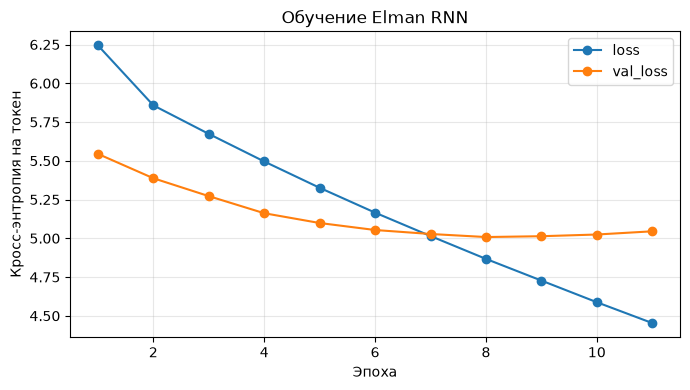

Валидационная потеря лучшей модели: 5.0081
Валидационная перплексия: 149.62


In [7]:
final_val_loss = run_epoch(val_loader, training=False)
perplexity = math.exp(final_val_loss)
assert math.isfinite(perplexity) and perplexity > 0

plt.figure(figsize=(7, 4))
epochs = range(1, len(history['loss']) + 1)
plt.plot(epochs, history['loss'], marker='o', label='loss')
plt.plot(epochs, history['val_loss'], marker='o', label='val_loss')
plt.xlabel('Эпоха')
plt.ylabel('Кросс-энтропия на токен')
plt.title('Обучение Elman RNN')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / 'learning_curve.png', dpi=140)
plt.show()

print(f'Валидационная потеря лучшей модели: {final_val_loss:.4f}')
print(f'Валидационная перплексия: {perplexity:.2f}')

## Этап 8. Проверка прогноза следующего слова и генерация

**Вход:** короткий текстовый запрос. Прогноз начинается с его
нормализации. Его слова
нормализуются и переводятся в индексы обучающего словаря; незнакомое
слово становится «<unk>». Последний логит последовательности описывает
распределение следующего токена. Функция top-$k$ выводит несколько
наиболее вероятных вариантов, а жадная генерация выбирает на каждом
шаге самый вероятный токен до «<eos>» или заданного лимита.

Не ожидайте литературного текста: маленький словарь, ограниченный
корпус и простая Elman RNN выбраны ради прозрачности вычислений.
Проверка корректности здесь — индексы принадлежат словарю, вероятности
конечны, а генерация останавливается не позднее лимита. **Порядок
действий:** запрос $\to$ нормализованные токены $\to$ индексы
$\to$ логиты последней позиции $\to$ softmax $\to$ top-$k$ либо
следующий индекс. Это уже применение обученной модели, а не
дополнительное обучение.

In [8]:
def prompt_to_ids(prompt: str) -> list[int]:
    tokens = normalize_and_tokenize(prompt, MAX_SEQUENCE_LENGTH - 1)
    return [BOS_IDX] + [stoi.get(token, UNK_IDX) for token in tokens]


@torch.no_grad()
def top_k_next_words(prompt: str, k: int = 5):
    input_ids = torch.tensor([prompt_to_ids(prompt)], dtype=torch.long, device=DEVICE)
    logits = model(input_ids)
    probabilities = torch.softmax(logits[0, -1], dim=-1)
    values, indices = torch.topk(probabilities, k=k)
    return [(itos[index.item()], value.item()) for value, index in zip(values, indices)]


@torch.no_grad()
def greedy_generate(prompt: str, max_new_tokens: int = 12) -> str:
    generated_ids = prompt_to_ids(prompt)
    for _ in range(max_new_tokens):
        model_input = torch.tensor([generated_ids], dtype=torch.long, device=DEVICE)
        next_id = int(torch.argmax(model(model_input)[0, -1]).item())
        if next_id == EOS_IDX:
            break
        generated_ids.append(next_id)
    visible_tokens = [
        itos[index]
        for index in generated_ids
        if index not in {PAD_IDX, BOS_IDX, EOS_IDX}
    ]
    return ' '.join(visible_tokens)


prompt = ' '.join(train_documents[0][:3])
predictions = top_k_next_words(prompt, k=5)
print('Top-k продолжений для запроса:', repr(prompt))
for token, probability in predictions:
    print(f'  {token:>18s}: {probability:.4f}')
print('Жадная генерация:', greedy_generate(prompt))
summary = {
    "dataset": DATASET_NAME, "revision": DATASET_REVISION,
    "train_documents": len(train_documents), "val_documents": len(val_documents),
    "train_fragments": len(train_pairs), "val_fragments": len(val_pairs),
    "vocab_size": VOCAB_SIZE, "parameters": sum(p.numel() for p in model.parameters()),
    "best_epoch": int(np.argmin(history["val_loss"]))+1,
    "epochs": len(history["loss"]), "val_loss": final_val_loss, "perplexity": perplexity,
    "history": history, "prompt": prompt, "top_k": predictions,
    "generation": greedy_generate(prompt), "seconds": time.perf_counter()-experiment_start,
    "python": sys.version.split()[0], "torch": torch.__version__, "datasets": datasets.__version__,
}
(ARTIFACT_DIR / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2))
(ARTIFACT_DIR / "vocabulary.json").write_text(json.dumps(itos, ensure_ascii=False, indent=2))
print("Итоги примера сохранены:", ARTIFACT_DIR)


Top-k продолжений для запроса: 'российское подразделение интернет-корпорации'
               <unk>: 0.2328
                   в: 0.0276
                  на: 0.0114
                 что: 0.0101
                   и: 0.0094
Жадная генерация: российское подразделение <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>
Итоги примера сохранены: artifacts/example


## Этап 9. Итоговая самопроверка

В этом примере были проверены все ключевые формы:
«input_ids» и «target_ids» имеют форму $(B,T)$, эмбеддинги и скрытые
состояния — $(B,T,128)$, логиты — $(B,T,V)$. Модель обучалась на
парах «предыдущие токены — следующий токен», а позиции заполнения
исключались из потери. Перед переходом к самостоятельному варианту
убедитесь, что потери и перплексия конечны, а лучшее состояние было
сохранено.